In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working in:", os.getcwd())

Working in: /Users/jamesfamodimu/Documents/energy-efficiency


In [2]:
from pathlib import Path
from itertools import combinations
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold, GroupKFold,
StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.mixture import GaussianMixture
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
roc_auc_score, brier_score_loss, accuracy_score, confusion_matrix)
import joblib
import json



SEED = 42


rng = np.random.default_rng(SEED)
pd.set_option("display.width", 110); pd.set_option("display.max_columns", 20)
for d in ["figures", "outputs", "model"]:
    Path(d).mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
"axes.spines.top": False, "axes.spines.right": False})
print("Setup is complete")

Setup is complete


In [3]:
from src.data import load_data, SEED, TARGETS, NUM, CAT, THRESH
df = load_data()
print(df.shape)

(768, 10)


In [4]:
target_values = df["heating_load"].values
sample_size = len(target_values)
distribution_metrics = []

distributions = {
    "Normal": stats.norm, 
    "Lognormal": stats.lognorm, 
    "Gamma": stats.gamma
}

for dist_name, distribution in distributions.items():
    if dist_name == "Normal":
        fit_parameters = distribution.fit(target_values)
    else:
        fit_parameters = distribution.fit(target_values, floc=0)
        
    log_likelihood = distribution.logpdf(target_values, *fit_parameters).sum()
    parameter_count = 2
    
    aic_score = 2 * parameter_count - 2 * log_likelihood
    bic_score = parameter_count * np.log(sample_size) - 2 * log_likelihood
    ks_p_value = stats.kstest(target_values, distribution.cdf, args = fit_parameters).pvalue
    
    distribution_metrics.append([dist_name, log_likelihood, aic_score, bic_score, ks_p_value])

reshaped_target = target_values.reshape(-1, 1)
gmm_model = GaussianMixture(n_components = 2, random_state = SEED).fit(reshaped_target)

mixture_weights = gmm_model.weights_
mixture_means = gmm_model.means_.ravel()
mixture_stds = np.sqrt(gmm_model.covariances_.ravel())

mixture_log_likelihood = gmm_model.score(reshaped_target) * sample_size
mixture_parameter_count = 5

mixture_aic = 2 * mixture_parameter_count - 2 * mixture_log_likelihood
mixture_bic = mixture_parameter_count * np.log(sample_size) - 2 * mixture_log_likelihood

def mixture_cdf(x):
    return sum(
        mixture_weights[i] * stats.norm.cdf(x, mixture_means[i], mixture_stds[i]) 
        for i in range(2)
    )

mixture_ks_p_value = stats.kstest(target_values, mixture_cdf).pvalue

distribution_metrics.append([
    "2-component mixture", 
    mixture_log_likelihood, 
    mixture_aic, 
    mixture_bic, 
    mixture_ks_p_value
])

columns_list = ["model", "loglik", "AIC", "BIC", "KS_p"]
model_fit_results = pd.DataFrame(distribution_metrics, columns=columns_list).sort_values(by="BIC")

print("Mixture means:", mixture_means.round(2), " sds:", mixture_stds.round(2))
print(model_fit_results.round(3))


Mixture means: [13.37 31.43]  sds: [2.68 5.77]
                 model    loglik       AIC       BIC   KS_p
3  2-component mixture -2639.352  5288.704  5311.923  0.281
2                Gamma -2819.191  5642.381  5651.669  0.000
1            Lognormal -2821.054  5646.109  5655.396  0.000
0               Normal -2864.526  5733.052  5742.339  0.000


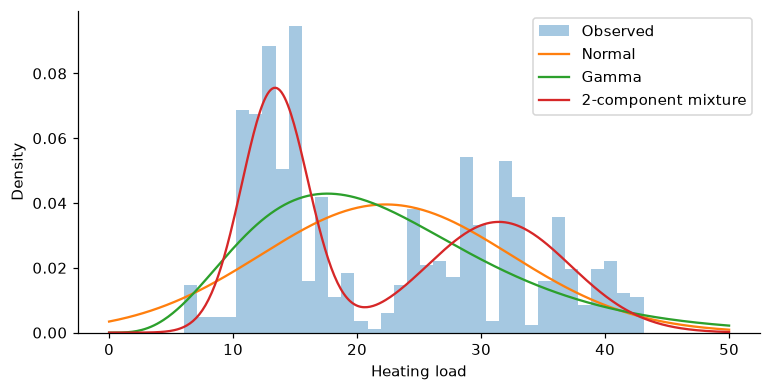

In [5]:
model_fit_results.round(3).to_csv("outputs/model_fits.csv", index = False)

x_sequence = np.linspace(start = 0, stop = 50, num = 400)
fig, ax = plt.subplots(figsize = (8, 3.8))

ax.hist(target_values, bins = 35, density = True, alpha = 0.4, label = "Observed")

normal_parameters = stats.norm.fit(target_values)
ax.plot(x_sequence, stats.norm.pdf(x_sequence, *normal_parameters), label = "Normal")

gamma_parameters = stats.gamma.fit(target_values, floc = 0)
ax.plot(x_sequence, stats.gamma.pdf(x_sequence, *gamma_parameters), label = "Gamma")

mixture_pdf_values = sum(
    mixture_weights[i] * stats.norm.pdf(x_sequence, mixture_means[i], mixture_stds[i]) 
    for i in range(2)
)
ax.plot(x_sequence, mixture_pdf_values, label = "2-component mixture")

ax.set_xlabel("Heating load")
ax.set_ylabel("Density")
ax.legend()

fig.savefig("figures/03_dist_fit.png")
plt.show()


In [6]:
for unique_height in [3.5, 7.0]:
    heating_load_subset = df.loc[df["height"] == unique_height, "heating_load"]
    shapiro_p_value = stats.shapiro(heating_load_subset).pvalue
    print(
        f"height {unique_height}: "
        f"mean {heating_load_subset.mean():.2f}, "
        f"sd {heating_load_subset.std():.2f}, "
        f"Shapiro p = {shapiro_p_value:.2e}"
    )

model_fit_results.to_csv("outputs/distribution_fits.csv", index = False)


height 3.5: mean 13.34, sd 2.67, Shapiro p = 7.79e-06
height 7.0: mean 31.28, sd 5.95, Shapiro p = 4.83e-05
